# Milestone 3 — Notebook 3: Errors and compute

This notebook Measures mistakes in the selected model and checks whether the model can be reproduced.

## 1. Read Milestone 2 data and restore Notebook 2 results


In [1]:
# Settings: the existing Milestone 2 files in GCS.
DATA_MODE = "gcs"
BUCKET_NAME = "conor-weekes-data-20084449"
FOLDER = f"gs://{BUCKET_NAME}/milestone2/processed"
LOCAL_FOLDER = "/content"
RANDOM_SEED = 42

if DATA_MODE == "gcs":
    !pip -q install gcsfs
    from google.colab import auth
    auth.authenticate_user()
else:
    FOLDER = LOCAL_FOLDER

In [2]:

import pandas as pd
import numpy as np

# Load processed CSV files from Milestone 2.
train = pd.read_csv(f"{FOLDER}/train_processed.csv")
dev = pd.read_csv(f"{FOLDER}/dev_processed.csv")
test = pd.read_csv(f"{FOLDER}/test_processed.csv")

features = ["fund_return_2017", "fund_return_2018", "fund_return_2019"]
target = "fund_return_2021_q1"


X_train = train[features]
y_train = train[target]

X_dev = dev[features]
y_dev = dev[target]


print("Training:", train.shape, "Development:", dev.shape, "Test:", test.shape)


Training: (18107, 5) Development: (2265, 5) Test: (2256, 5)


In [3]:

import json
from pathlib import Path
from google.cloud import storage

results_folder = Path("/content/m3_results")
results_folder.mkdir(exist_ok=True)

# Download the selected model from Google Cloud Storage.
client = storage.Client()
bucket = client.bucket(BUCKET_NAME)

files_to_download = [
    "selected_model.pt",
    "selected_model.json"
]

for filename in files_to_download:
    cloud_path = f"milestone3/{filename}"
    local_path = results_folder / filename

    blob = bucket.blob(cloud_path)
    blob.download_to_filename(str(local_path))

    print("Downloaded:", filename)

# Read the selected model information.
selection = json.loads((results_folder / "selected_model.json").read_text())
chosen = selection["best_run"]

print("Chosen model:", chosen["model_type"])
print("Development MAE:", chosen["dev_mae"])


Downloaded: selected_model.pt
Downloaded: selected_model.json
Chosen model: PyTorch
Development MAE: 0.027599377557635307


## 2. Load the saved model

In [4]:

import torch
import numpy as np
from torch import nn

class FundMLP(nn.Module):
    def __init__(self, hidden_size):
        super(FundMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(3, hidden_size),
            nn.Sigmoid(),
            nn.Linear(hidden_size, hidden_size),
            nn.Sigmoid(),
            nn.Linear(hidden_size, hidden_size),
            nn.Sigmoid(),
            nn.Linear(hidden_size, 1)
        )

    def forward(self, x):
        return self.network(x)

# Reconstruct the selected model.
model = FundMLP(int(chosen["hidden_size"]))

# Load the saved model weights.
model.load_state_dict(
    torch.load(
        results_folder / "selected_model.pt",
        map_location="cpu",
        weights_only=True
    )
)

model.eval()

# Make predictions using the saved model.
def predict(X):
    X_t = torch.FloatTensor(np.array(X).astype(np.float32))

    with torch.no_grad():
        return model(X_t).numpy().flatten()

pred = predict(X_dev)

print("Loaded saved model. Development predictions:", len(pred))


Loaded saved model. Development predictions: 2265


## 3. Find the biggest model errors

Inspect funds with the largest differences between actual and predicted returns.

In [5]:

from sklearn.metrics import mean_absolute_error

# Compare actual returns with predicted returns.
errors = pd.DataFrame({
    "fund_symbol": dev["fund_symbol"],
    "actual": y_dev,
    "predicted": pred
})

# Calculate prediction errors.
errors["absolute_error"] = abs(errors["actual"] - errors["predicted"])

mae = mean_absolute_error(y_dev, pred)

print("Development MAE:", round(mae * 100, 3), "percentage points")

# Show the 10 funds with the largest errors.
display(errors.sort_values("absolute_error", ascending=False).head(10))

# Save results.
errors.to_csv(results_folder / "development_errors.csv", index=False)


Development MAE: 2.76 percentage points


,fund_symbol,actual,predicted,absolute_error
1998,AMREX,0.42520,0.109877,0.315323
1118,AVUVX,0.26238,0.039195,0.223185
1677,HWVZX,0.24745,0.039195,0.208255
816,JSCGX,0.22634,0.020310,0.206030
943,PEDPX,-0.17892,0.023366,0.202286
581,WFICX,0.24553,0.044134,0.201396
679,SGDIX,-0.14415,0.039195,0.183345
2263,TRZUX,-0.13257,0.039195,0.171765
1265,GLDCX,-0.13849,0.030022,0.168512
817,QSPIX,0.19811,0.031746,0.166364


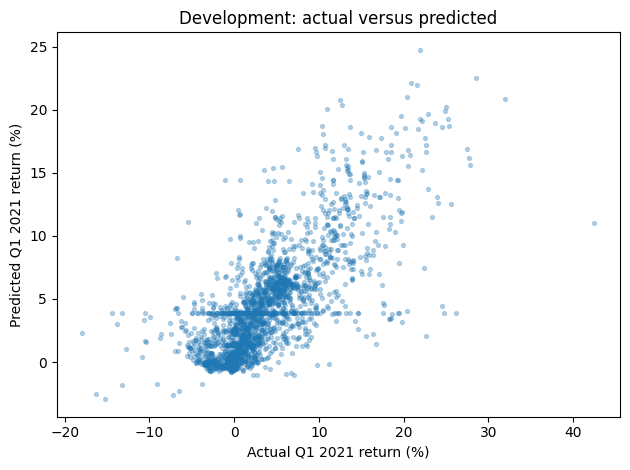

In [6]:
import matplotlib.pyplot as plt

plt.scatter(y_dev * 100, pred * 100, s=8, alpha=0.3)
plt.xlabel("Actual Q1 2021 return (%)")
plt.ylabel("Predicted Q1 2021 return (%)")
plt.title("Development: actual versus predicted")
plt.tight_layout()
plt.savefig(results_folder / "errors_plot.png")
plt.show()

## 4. Final test evaluation

In [10]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_test = test[features]
y_test = test[target]

pred_test = predict(X_test)

mae = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(mean_squared_error(y_test, pred_test))
r2 = r2_score(y_test, pred_test)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)


MAE: 0.027898320030492883
RMSE: 0.04292478546448354
R2: 0.4956560067321337
